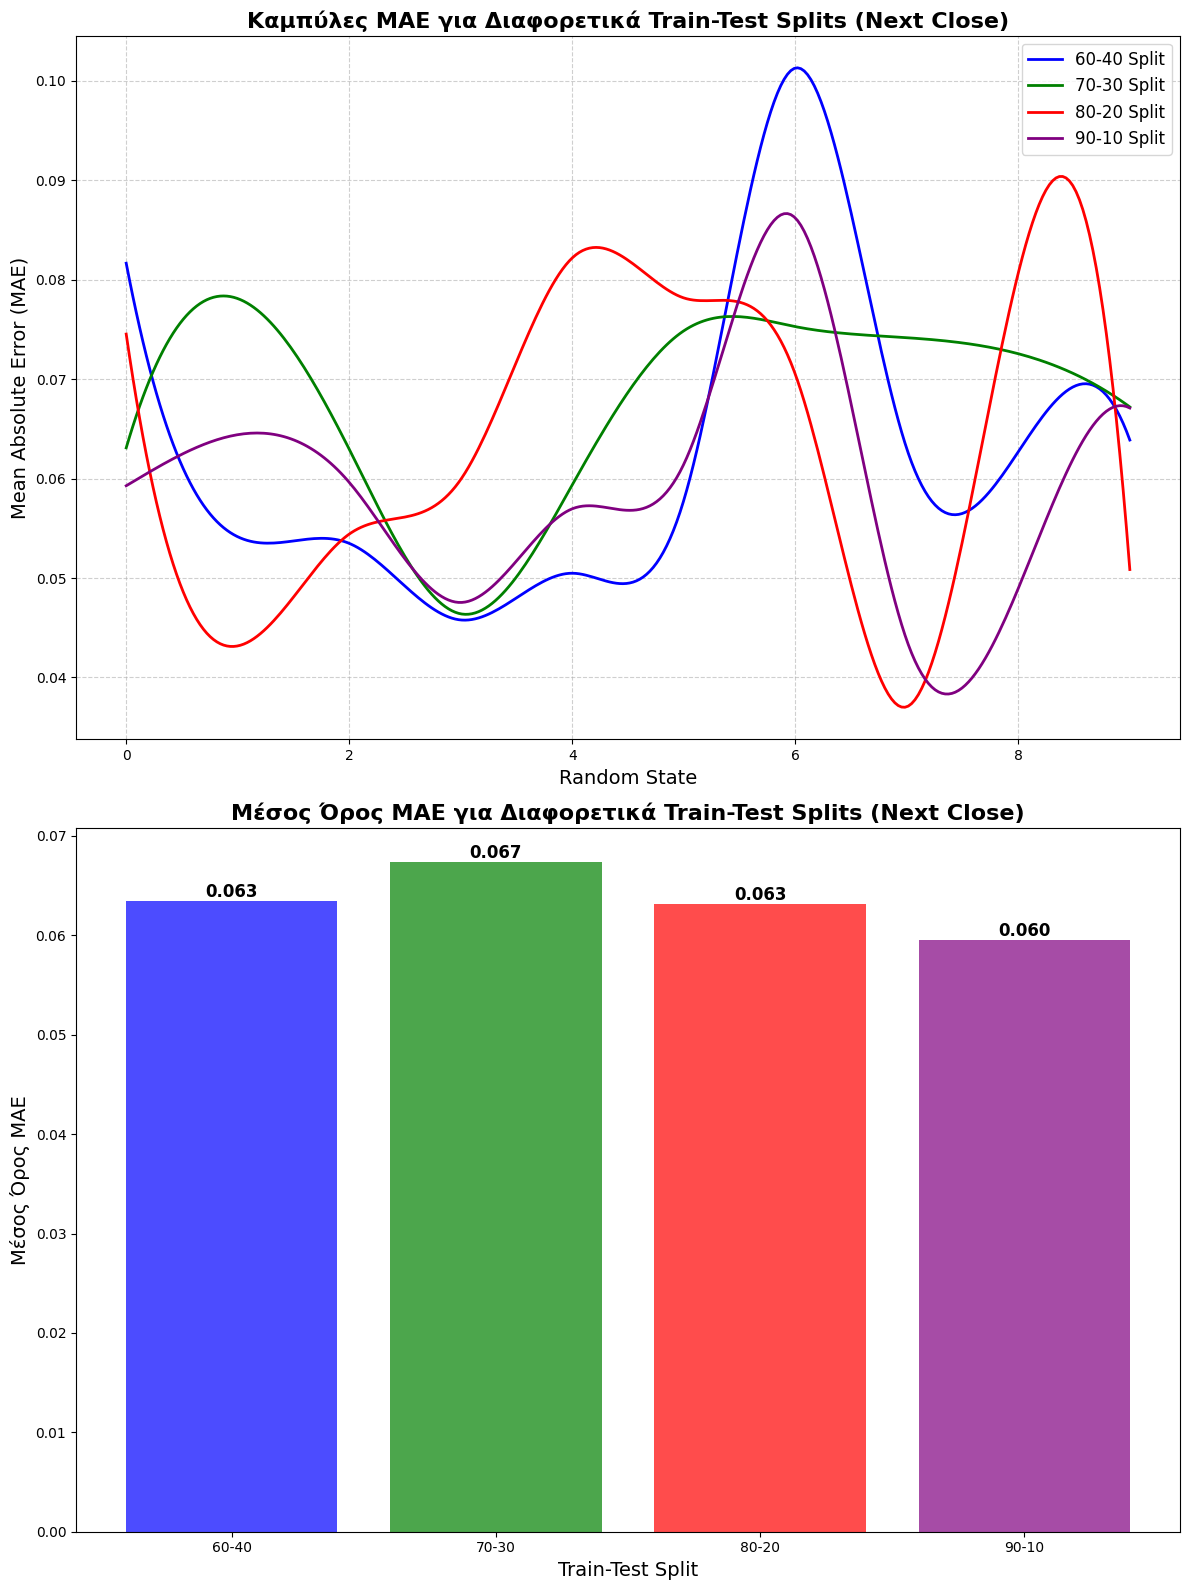

In [1]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 =np.array([
    0.08165797232629068, 0.05414902276618593, 0.05348448950406384,
    0.04578252314039497, 0.050481364667304206, 0.057813084798722866,
    0.10128344853324094, 0.06299872759157168, 0.06269836987186977,
    0.06387668013987215
])
mae_70_30 = np.array([
    0.06308816129927994, 0.07810034880442546, 0.06295336886580084,
    0.04639722340115767, 0.05936638785706807, 0.07485794694526607,
    0.07528104877335777, 0.07416728579533632, 0.07255531887737565,
    0.06720245091121985
])
mae_80_20 = np.array([
    0.07453100719361772, 0.04317197723290086, 0.05441730830542027,
    0.05991087262763072, 0.08219247951438306, 0.07816881498992896,
    0.07049359018359505, 0.03705147832783862, 0.08068414555021054,
    0.05085259715299653
])
mae_90_10 = np.array([
    0.059277712591052, 0.06441550569866328, 0.05962052213335638,
    0.04754073188828234, 0.056961818229698244, 0.06144181284511164,
    0.0862103577340549, 0.04372553198362264, 0.04896231532954795,
    0.06709535091949691
])

# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)


axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Next Close)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Next Close)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()
